In [1]:
from pathlib import Path
import warnings
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, joblib
from sklearn.model_selection import train_test_split, StratifiedKFold, RandomizedSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, classification_report, ConfusionMatrixDisplay, confusion_matrix
RANDOM_STATE=42

In [2]:
PROJECT_ROOT=Path.cwd() if (Path.cwd()/"Data").exists() else Path.cwd().parent
path=PROJECT_ROOT/"Data/Original/train.csv"
if path is None: raise FileNotFoundError("Put train.csv in Data/Original")
df=pd.read_csv(path)
print(df.shape)
display(df.head())

(165034, 14)


,id,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,0,15674932,Okwudilichukwu,668,France,Male,33.0,3,0.00,2,1.0,0.0,181449.97,0
1,1,15749177,Okwudiliolisa,627,France,Male,33.0,1,0.00,2,1.0,1.0,49503.50,0
2,2,15694510,Hsueh,678,France,Male,40.0,10,0.00,2,1.0,0.0,184866.69,0
3,3,15741417,Kao,581,France,Male,34.0,2,148882.54,1,1.0,1.0,84560.88,0
4,4,15766172,Chiemenam,716,Spain,Male,33.0,5,0.00,2,1.0,1.0,15068.83,0


In [3]:
TARGET="Exited"
print(df[TARGET].value_counts())
print(df[TARGET].value_counts(normalize=True).mul(100).round(2))

Exited
0    130113
1     34921
Name: count, dtype: int64
Exited
0    78.84
1    21.16
Name: proportion, dtype: float64


In [4]:
DROP=["id","CustomerId","Surname"]
X0=df.drop(columns=[TARGET]+DROP)
y=df[TARGET].astype(int)
print(X0.shape,y.shape)

(165034, 10) (165034,)


In [5]:
def engineer_features(frame):
    z=frame.copy()
    z["Age_Group"]=pd.cut(z["Age"],[0,25,40,55,120],labels=["18-24","25-39","40-54","55+"],right=False)
    z["Tenure_Group"]=pd.cut(z["Tenure"],[-1,2,5,10],labels=["0-2","3-5","6-10"])
    z["HasBalance"]=(z["Balance"]>0).astype(int)
    return z
X=engineer_features(X0)
display(X.head())

,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Age_Group,Tenure_Group,HasBalance
0,668,France,Male,33.0,3,0.00,2,1.0,0.0,181449.97,25-39,3-5,0
1,627,France,Male,33.0,1,0.00,2,1.0,1.0,49503.50,25-39,0-2,0
2,678,France,Male,40.0,10,0.00,2,1.0,0.0,184866.69,40-54,6-10,0
3,581,France,Male,34.0,2,148882.54,1,1.0,1.0,84560.88,25-39,0-2,1
4,716,Spain,Male,33.0,5,0.00,2,1.0,1.0,15068.83,25-39,3-5,0


In [6]:
NUM=["CreditScore","Age","Tenure","Balance","NumOfProducts","HasCrCard","IsActiveMember","EstimatedSalary","HasBalance"]
CAT=["Geography","Gender","Age_Group","Tenure_Group"]
print("Numeric:",len(NUM),"Categorical:",len(CAT))

Numeric: 9 Categorical: 4


In [7]:
X_train,X_valid,y_train,y_valid=train_test_split(X,y,test_size=.20,random_state=RANDOM_STATE,stratify=y)
print(X_train.shape,X_valid.shape)
print(y_train.mean(),y_valid.mean())

(132027, 13) (33007, 13)
0.21160065744128095 0.2115914805950253


In [8]:
def make_preprocessor(scale=False):
    numeric=[("imputer",SimpleImputer(strategy="median"))]
    if scale: numeric.append(("scaler",StandardScaler()))
    categorical=[("imputer",SimpleImputer(strategy="most_frequent")),("encoder",OneHotEncoder(handle_unknown="ignore"))]
    return ColumnTransformer([("numeric",Pipeline(numeric),NUM),("categorical",Pipeline(categorical),CAT)])

In [9]:
sample_ids=X_train.sample(n=min(24000,len(X_train)),random_state=RANDOM_STATE).index
X_cv,y_cv=X_train.loc[sample_ids],y_train.loc[sample_ids]
cv=StratifiedKFold(n_splits=3,shuffle=True,random_state=RANDOM_STATE)
print(X_cv.shape)

(24000, 13)


In [10]:
lr_search=RandomizedSearchCV(
 Pipeline([("prep",make_preprocessor(True)),("model",LogisticRegression(max_iter=1200,class_weight="balanced",solver="liblinear"))]),
 {"model__C":[.05,.1,.5,1,2,5]},n_iter=4,scoring="f1",cv=cv,random_state=42,n_jobs=-1)
lr_search.fit(X_cv,y_cv)
print(lr_search.best_params_,lr_search.best_score_)

{'model__C': 5} 0.5585404781403841


In [11]:
dt_search=RandomizedSearchCV(
 Pipeline([("prep",make_preprocessor()),("model",DecisionTreeClassifier(class_weight="balanced",random_state=42))]),
 {"model__max_depth":[4,6,8,10,None],"model__min_samples_leaf":[10,20,40,80]},
 n_iter=5,scoring="f1",cv=cv,random_state=42,n_jobs=-1)
dt_search.fit(X_cv,y_cv)
print(dt_search.best_params_,dt_search.best_score_)

{'model__min_samples_leaf': 80, 'model__max_depth': 10} 0.6209431883294773


In [12]:
models={
 "Logistic Regression":Pipeline([("prep",make_preprocessor(True)),("model",LogisticRegression(C=lr_search.best_params_["model__C"],max_iter=1200,class_weight="balanced",solver="liblinear"))]),
 "Decision Tree":Pipeline([("prep",make_preprocessor()),("model",DecisionTreeClassifier(max_depth=dt_search.best_params_["model__max_depth"],min_samples_leaf=dt_search.best_params_["model__min_samples_leaf"],class_weight="balanced",random_state=42))]),
 "Random Forest":Pipeline([("prep",make_preprocessor()),("model",RandomForestClassifier(n_estimators=100,min_samples_leaf=3,class_weight="balanced_subsample",random_state=42,n_jobs=-1))]),
 "Extra Trees":Pipeline([("prep",make_preprocessor()),("model",ExtraTreesClassifier(n_estimators=100,min_samples_leaf=3,class_weight="balanced",random_state=42,n_jobs=-1))])
}
print(list(models))

['Logistic Regression', 'Decision Tree', 'Random Forest', 'Extra Trees']


In [13]:
fitted={}
predictions={}
for name,pipe in models.items():
    pipe.fit(X_train,y_train)
    predictions[name]=(pipe.predict(X_valid),pipe.predict_proba(X_valid)[:,1])
    fitted[name]=pipe
    print(name,"trained")

Logistic Regression trained
Decision Tree trained
Random Forest trained
Extra Trees trained


In [14]:
rows=[]
for name,(pred,prob) in predictions.items():
    rows.append({"Model":name,"Accuracy":accuracy_score(y_valid,pred),"Precision":precision_score(y_valid,pred,zero_division=0),"Recall":recall_score(y_valid,pred,zero_division=0),"F1":f1_score(y_valid,pred,zero_division=0),"ROC_AUC":roc_auc_score(y_valid,prob)})
results=pd.DataFrame(rows).sort_values("F1",ascending=False).reset_index(drop=True)
display(results.round(4))

,Model,Accuracy,Precision,Recall,F1,ROC_AUC
0,Random Forest,0.8487,0.6360,0.6661,0.6507,0.8784
1,Extra Trees,0.8239,0.5630,0.7500,0.6432,0.8792
2,Decision Tree,0.8076,0.5305,0.7869,0.6338,0.8815
3,Logistic Regression,0.7599,0.4581,0.7363,0.5648,0.8227


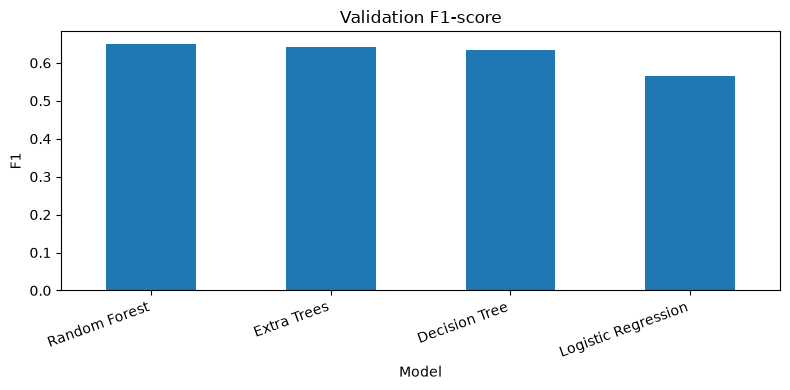

Selected model: Random Forest


In [15]:
ax=results.set_index("Model")["F1"].plot(kind="bar",figsize=(8,4),title="Validation F1-score")
ax.set_ylabel("F1"); plt.xticks(rotation=20,ha="right"); plt.tight_layout(); plt.show()
best_name=results.iloc[0]["Model"]
print("Selected model:",best_name)

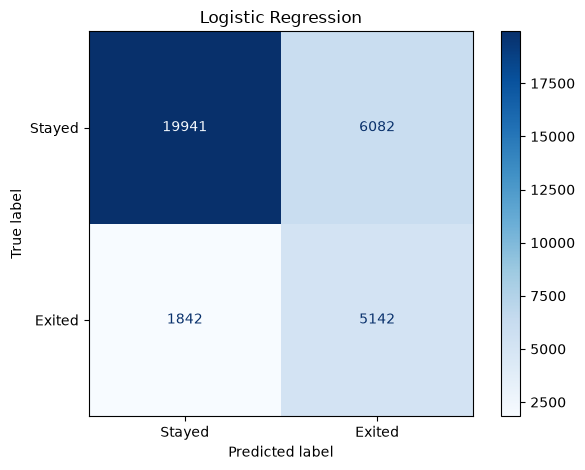

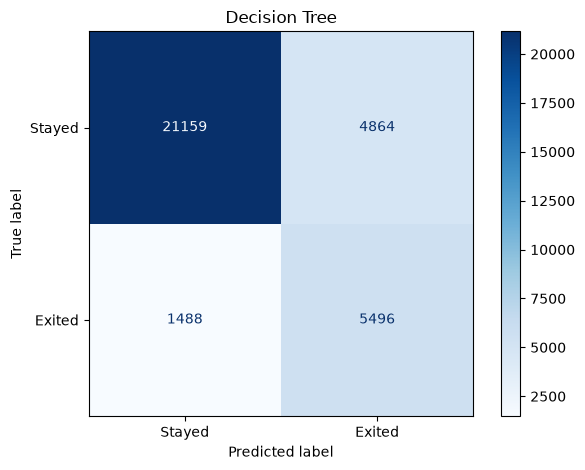

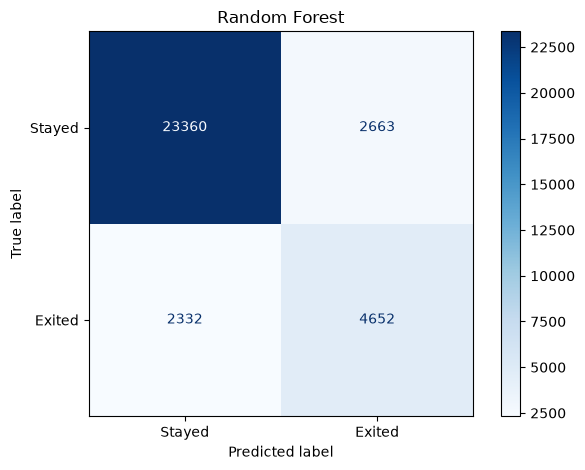

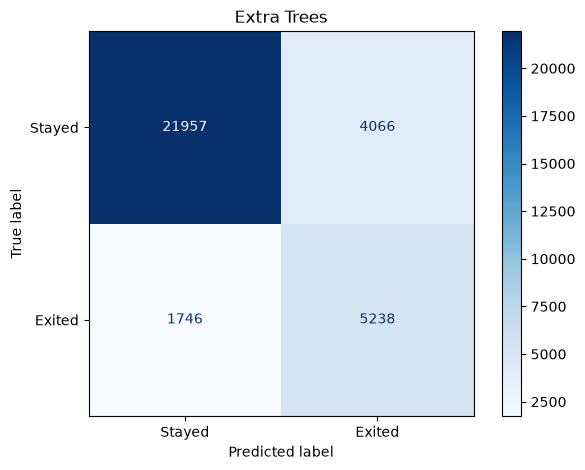

In [16]:
for name,(pred,prob) in predictions.items():
    ConfusionMatrixDisplay.from_predictions(y_valid,pred,display_labels=["Stayed","Exited"],cmap="Blues",values_format="d")
    plt.title(name); plt.tight_layout(); plt.show()

In [17]:
best_pred,best_prob=predictions[best_name]
print(classification_report(y_valid,best_pred,target_names=["Stayed","Exited"],zero_division=0))

              precision    recall  f1-score   support

      Stayed       0.91      0.90      0.90     26023
      Exited       0.64      0.67      0.65      6984

    accuracy                           0.85     33007
   macro avg       0.77      0.78      0.78     33007
weighted avg       0.85      0.85      0.85     33007



In [18]:
tn,fp,fn,tp=confusion_matrix(y_valid,best_pred).ravel()
print({"True negatives":tn,"False positives":fp,"False negatives":fn,"True positives":tp})

{'True negatives': np.int64(23360), 'False positives': np.int64(2663), 'False negatives': np.int64(2332), 'True positives': np.int64(4652)}


In [19]:
MODEL_DIR=PROJECT_ROOT/"Models"; MODEL_DIR.mkdir(exist_ok=True)
for name,pipe in fitted.items():
    joblib.dump(pipe,MODEL_DIR/(name.lower().replace(" ","_")+".joblib"))
results.to_csv(MODEL_DIR/"model_comparison.csv",index=False)
print("Saved:",[p.name for p in MODEL_DIR.glob("*.joblib")])

Saved: ['decision_tree.joblib', 'extra_trees.joblib', 'logistic_regression.joblib', 'project_config.joblib', 'random_forest.joblib']


In [20]:
config={"target":TARGET,"dropped_identifiers":DROP,"numeric_features":NUM,"categorical_features":CAT,"random_state":42,"default_model":best_name}
joblib.dump(config,MODEL_DIR/"project_config.joblib")
print(config)

{'target': 'Exited', 'dropped_identifiers': ['id', 'CustomerId', 'Surname'], 'numeric_features': ['CreditScore', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary', 'HasBalance'], 'categorical_features': ['Geography', 'Gender', 'Age_Group', 'Tenure_Group'], 'random_state': 42, 'default_model': 'Random Forest'}


In [21]:
test_path=PROJECT_ROOT/"Data/Original/test.csv"
if test_path.exists():
    test_df=pd.read_csv(test_path)
    test_X=engineer_features(test_df.drop(columns=DROP))
    test_pred=fitted[best_name].predict(test_X)
    submission=pd.DataFrame({"id":test_df["id"],"Exited":test_pred})
    submission.to_csv(PROJECT_ROOT/"Data/Processed/submission_predictions.csv",index=False)
    display(submission.head())
else:
    print("test.csv not found")

,id,Exited
0,165034,0
1,165035,1
2,165036,0
3,165037,0
4,165038,0


In [22]:
display(results.round(4))
print("Chosen model based on F1:",best_name)

,Model,Accuracy,Precision,Recall,F1,ROC_AUC
0,Random Forest,0.8487,0.6360,0.6661,0.6507,0.8784
1,Extra Trees,0.8239,0.5630,0.7500,0.6432,0.8792
2,Decision Tree,0.8076,0.5305,0.7869,0.6338,0.8815
3,Logistic Regression,0.7599,0.4581,0.7363,0.5648,0.8227


Chosen model based on F1: Random Forest


In [23]:
print("Validation rows:",len(y_valid))
print("Test data is unlabeled and must not be included in validation metrics.")

Validation rows: 33007
Test data is unlabeled and must not be included in validation metrics.


In [24]:
display(pd.DataFrame({'train':y_train.value_counts(normalize=True),'validation':y_valid.value_counts(normalize=True)}).sort_index())

,train,validation
Exited,,
0,0.788399,0.788409
1,0.211601,0.211591


In [25]:
assert set(y.unique())=={0,1}; print('Target is binary.')

Target is binary.


In [26]:
assert list(X_train.columns)==list(X_valid.columns); print('Feature columns align.')

Feature columns align.


In [27]:
print(lr_search.best_params_); print('CV F1:',lr_search.best_score_)

{'model__C': 5}
CV F1: 0.5585404781403841


In [28]:
print(dt_search.best_params_); print('CV F1:',dt_search.best_score_)

{'model__min_samples_leaf': 80, 'model__max_depth': 10}
CV F1: 0.6209431883294773


In [29]:
display(results[['Model','Precision']].sort_values('Precision',ascending=False))

,Model,Precision
0,Random Forest,0.635954
1,Extra Trees,0.562984
2,Decision Tree,0.530502
3,Logistic Regression,0.458125


In [30]:
display(results[['Model','Recall']].sort_values('Recall',ascending=False))

,Model,Recall
2,Decision Tree,0.786942
1,Extra Trees,0.750000
3,Logistic Regression,0.736254
0,Random Forest,0.666094


In [31]:
display(results[['Model','ROC_AUC']].sort_values('ROC_AUC',ascending=False))

,Model,ROC_AUC
2,Decision Tree,0.881452
1,Extra Trees,0.879189
0,Random Forest,0.878395
3,Logistic Regression,0.822716


In [32]:
display(results[['Model','Accuracy']].sort_values('Accuracy',ascending=False))

,Model,Accuracy
0,Random Forest,0.848668
1,Extra Trees,0.823916
2,Decision Tree,0.807556
3,Logistic Regression,0.759930


In [33]:
print('Total validation predictions:',tn+fp+fn+tp)

Total validation predictions: 33007


In [34]:
display(pd.read_csv(MODEL_DIR/'model_comparison.csv'))

,Model,Accuracy,Precision,Recall,F1,ROC_AUC
0,Random Forest,0.848668,0.635954,0.666094,0.650675,0.878395
1,Extra Trees,0.823916,0.562984,0.750000,0.643173,0.879189
2,Decision Tree,0.807556,0.530502,0.786942,0.633764,0.881452
3,Logistic Regression,0.759930,0.458125,0.736254,0.564807,0.822716


In [35]:
print('Random state = 42; stratified split and CV are reproducible.')

Random state = 42; stratified split and CV are reproducible.


In [36]:
print('Because the classes are imbalanced, accuracy is considered together with recall, precision and F1.')

Because the classes are imbalanced, accuracy is considered together with recall, precision and F1.


In [37]:
print('Pipeline keeps learned transformations inside each training fold and reduces leakage risk.')

Pipeline keeps learned transformations inside each training fold and reduces leakage risk.


In [38]:
print('The unlabeled test file is reserved for generating competition predictions only.')

The unlabeled test file is reserved for generating competition predictions only.
